<center><h1>Last_First_HW8</h1></center>

Name: Jerry(Juifan) Lin
<br>
Github Username: JiaLiiin
<br>
USC ID: 9985422205

## 1. Supervised, Semi-Supervised, and Unsupervised Learning

Import packages

In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import Normalizer, StandardScaler
from sklearn.svm import LinearSVC
from sklearn.cluster import KMeans, SpectralClustering
from sklearn.neighbors import NearestCentroid
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    ConfusionMatrixDisplay,
)
from scipy.special import softmax
from scipy.spatial.distance import cdist

### (a) Download the Breast Cancer Wisconsin (Diagnostic) Data Set

In [23]:
col_names = ["ID", "Diagnosis"] + [f"feature_{i}" for i in range(1, 31)]
wdbc = pd.read_csv("../Data/wdbc.data", header=None, names=col_names)

X_wdbc = wdbc.iloc[:, 2:].values
y_wdbc = (wdbc["Diagnosis"] == "M").astype(int).values

print("Dataset shape:", X_wdbc.shape)
print("Class distribution (0=Benign, 1=Malignant):", np.bincount(y_wdbc))

Dataset shape: (569, 30)
Class distribution (0=Benign, 1=Malignant): [357 212]


### (b) Monte-Carlo Simulation

#### (i) Supervised Learning

c:\Users\admins\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:1298: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
c:\Users\admins\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:1298: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
c:\Users\admins\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:1298: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
c:\Users\admins\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:1298: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
c:\Users\admins\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:1298: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  

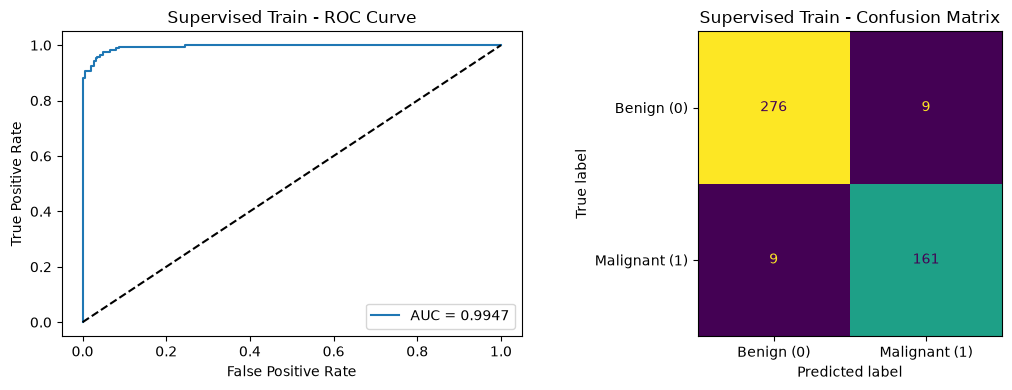

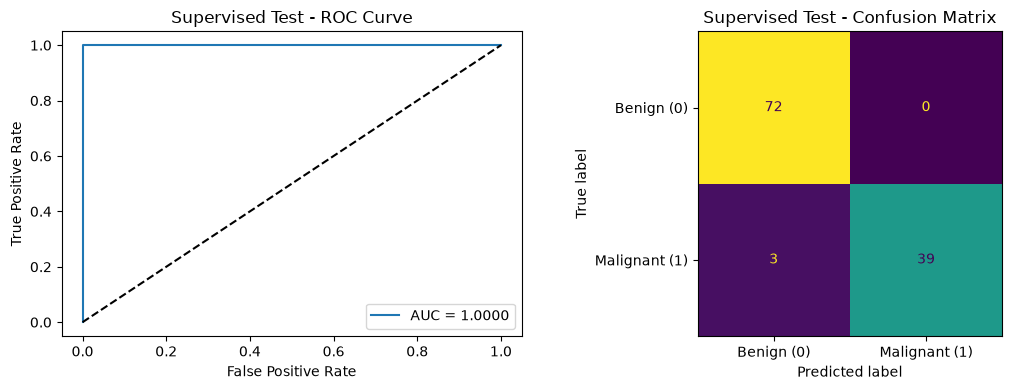

              Train      Test
accuracy   0.981465  0.956433
precision  0.980470  0.951173
recall     0.969804  0.930159
f1         0.975083  0.940004
auc        0.998041  0.992295


In [24]:
def evaluate_metrics(y_true, y_pred, y_score):
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "auc": roc_auc_score(y_true, y_score),
    }

def plot_roc_and_cm(y_true, y_pred, y_score, title_prefix):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    fpr, tpr, _ = roc_curve(y_true, y_score)
    auc_val = roc_auc_score(y_true, y_score)
    axes[0].plot(fpr, tpr, label=f"AUC = {auc_val:.4f}")
    axes[0].plot([0, 1], [0, 1], "k--")
    axes[0].set_xlabel("False Positive Rate")
    axes[0].set_ylabel("True Positive Rate")
    axes[0].set_title(f"{title_prefix} - ROC Curve")
    axes[0].legend(loc="lower right")
    cm = confusion_matrix(y_true, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Benign (0)", "Malignant (1)"])
    disp.plot(ax=axes[1], colorbar=False)
    axes[1].set_title(f"{title_prefix} - Confusion Matrix")
    
    plt.tight_layout()
    plt.show()

M = 30
C_grid = {"C": np.logspace(-3, 4, 20)}

sup_train_metrics, sup_test_metrics = [], []

for m in range(M):
    X_train, X_test, y_train, y_test = train_test_split(
        X_wdbc, y_wdbc, test_size=0.2, stratify=y_wdbc, random_state=m
    )
    scaler = Normalizer()
    X_train_norm = scaler.fit_transform(X_train)
    X_test_norm = scaler.transform(X_test)
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=m)
    clf = GridSearchCV(
        LinearSVC(penalty="l1", dual=False, max_iter=10000, random_state=m),
        param_grid=C_grid,
        cv=cv,
        n_jobs=-1,
    )
    clf.fit(X_train_norm, y_train)
    best_svm = clf.best_estimator_
    train_pred = best_svm.predict(X_train_norm)
    train_score = best_svm.decision_function(X_train_norm)
    test_pred = best_svm.predict(X_test_norm)
    test_score = best_svm.decision_function(X_test_norm)
    sup_train_metrics.append(evaluate_metrics(y_train, train_pred, train_score))
    sup_test_metrics.append(evaluate_metrics(y_test, test_pred, test_score))
    if m == M - 1:
        plot_roc_and_cm(y_train, train_pred, train_score, "Supervised Train")
        plot_roc_and_cm(y_test, test_pred, test_score, "Supervised Test")

sup_train_df = pd.DataFrame(sup_train_metrics).mean()
sup_test_df = pd.DataFrame(sup_test_metrics).mean()
print(pd.DataFrame({"Train": sup_train_df, "Test": sup_test_df}))

#### (ii) Semi-Supervised Learning/ Self-training

##### (A)

In [25]:
semi_splits = []

for m in range(M):
    X_train, X_test, y_train, y_test = train_test_split(
        X_wdbc, y_wdbc, test_size=0.2, stratify=y_wdbc, random_state=m
    )
    
    scaler = Normalizer()
    X_train_norm = scaler.fit_transform(X_train)
    X_test_norm = scaler.transform(X_test)
    
    X_lab, X_unlab, y_lab, _ = train_test_split(
        X_train_norm, y_train, test_size=0.5, stratify=y_train, random_state=m
    )

    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=m)
    clf = GridSearchCV(
        LinearSVC(penalty="l1", dual=False, max_iter=10000, random_state=m),
        param_grid=C_grid,
        cv=cv,
        n_jobs=-1,
    )
    clf.fit(X_lab, y_lab)
    
    semi_splits.append({
        "X_train_norm": X_train_norm,
        "y_train": y_train,
        "X_test_norm": X_test_norm,
        "y_test": y_test,
        "X_lab": X_lab,
        "y_lab": y_lab,
        "X_unlab": X_unlab,
        "best_C": clf.best_params_["C"],
        "best_estimator": clf.best_estimator_,
    })

print(f"Completed initial labeled SVM training across M={M} runs.")
print(f"Example Run 0 Best C: {semi_splits[0]['best_C']:.4f}")

c:\Users\admins\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:1298: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
c:\Users\admins\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:1298: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
c:\Users\admins\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:1298: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
c:\Users\admins\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:1298: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
c:\Users\admins\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:1298: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  

Completed initial labeled SVM training across M=30 runs.
Example Run 0 Best C: 4281.3324


c:\Users\admins\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:1298: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


##### (B)

c:\Users\admins\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:1298: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
c:\Users\admins\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:1298: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
c:\Users\admins\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:1298: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
c:\Users\admins\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:1298: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
c:\Users\admins\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:1298: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  

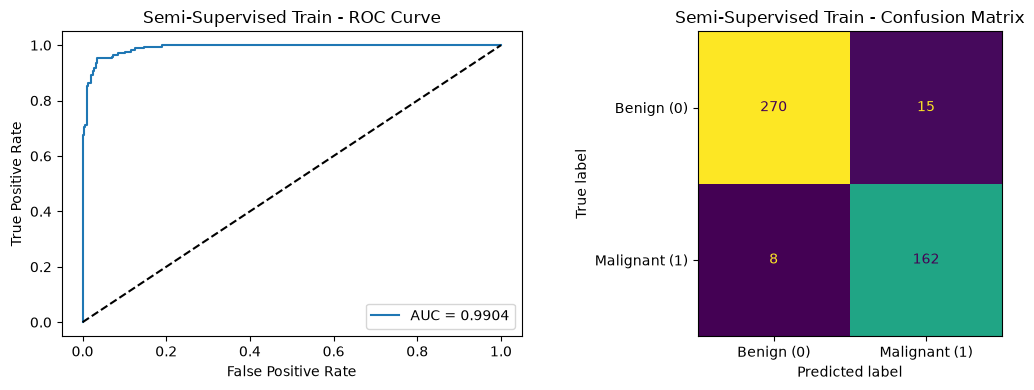

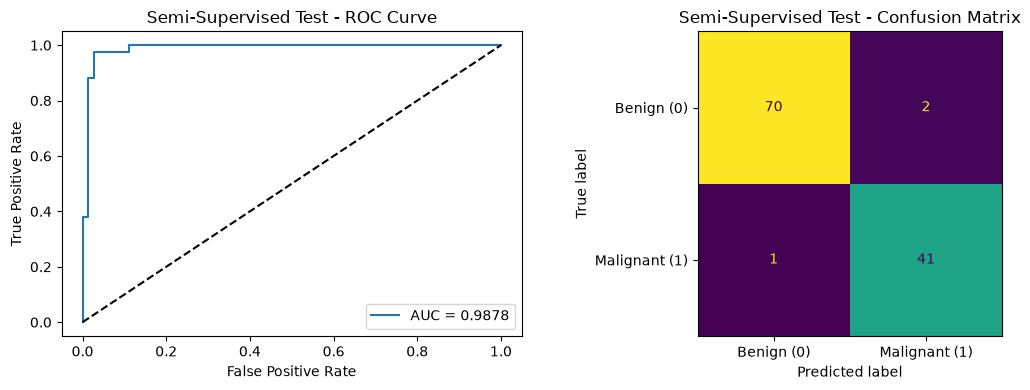

              Train      Test
accuracy   0.962930  0.941228
precision  0.954087  0.933484
recall     0.946667  0.907143
f1         0.950056  0.918656
auc        0.992434  0.985560


In [26]:
semi_train_metrics, semi_test_metrics = [], []

for m, data in enumerate(semi_splits):
    X_lab_curr = data["X_lab"].copy()
    y_lab_curr = data["y_lab"].copy()
    X_unlab_curr = data["X_unlab"].copy()
    best_C = data["best_C"]
    
    svm = LinearSVC(penalty="l1", dual=False, C=best_C, max_iter=10000, random_state=m)
    svm.fit(X_lab_curr, y_lab_curr)
    
    while len(X_unlab_curr) > 0:
        distances = np.abs(svm.decision_function(X_unlab_curr))
        farthest_idx = np.argmax(distances)
        
        x_next = X_unlab_curr[farthest_idx : farthest_idx + 1]
        y_pseudo = svm.predict(x_next)
        
        X_lab_curr = np.vstack([X_lab_curr, x_next])
        y_lab_curr = np.concatenate([y_lab_curr, y_pseudo])
        X_unlab_curr = np.delete(X_unlab_curr, farthest_idx, axis=0)
        
        svm.fit(X_lab_curr, y_lab_curr)
        
    train_pred = svm.predict(data["X_train_norm"])
    train_score = svm.decision_function(data["X_train_norm"])
    test_pred = svm.predict(data["X_test_norm"])
    test_score = svm.decision_function(data["X_test_norm"])
    
    semi_train_metrics.append(evaluate_metrics(data["y_train"], train_pred, train_score))
    semi_test_metrics.append(evaluate_metrics(data["y_test"], test_pred, test_score))
    
    if m == M - 1:
        plot_roc_and_cm(data["y_train"], train_pred, train_score, "Semi-Supervised Train")
        plot_roc_and_cm(data["y_test"], test_pred, test_score, "Semi-Supervised Test")

semi_train_df = pd.DataFrame(semi_train_metrics).mean()
semi_test_df = pd.DataFrame(semi_test_metrics).mean()
print(pd.DataFrame({"Train": semi_train_df, "Test": semi_test_df}))

#### (iii) Unsupervised Learning

##### (A)

In [27]:
kmeans_runs = []

for m in range(M):
    X_train, X_test, y_train, y_test = train_test_split(
        X_wdbc, y_wdbc, test_size=0.2, stratify=y_wdbc, random_state=m
    )
    
    scaler = Normalizer()
    X_train_norm = scaler.fit_transform(X_train)
    X_test_norm = scaler.transform(X_test)
    km = KMeans(n_clusters=2, init="random", n_init=50, random_state=m)
    train_clusters = km.fit_predict(X_train_norm)
    
    kmeans_runs.append({
        "X_train_norm": X_train_norm,
        "y_train": y_train,
        "X_test_norm": X_test_norm,
        "y_test": y_test,
        "train_clusters": train_clusters,
        "centers": km.cluster_centers_,
        "inertia": km.inertia_,
    })
print(f"Example Run 0 Lowest Inertia: {kmeans_runs[0]['inertia']:.4f}")

Example Run 0 Lowest Inertia: 1.2052


##### (B)

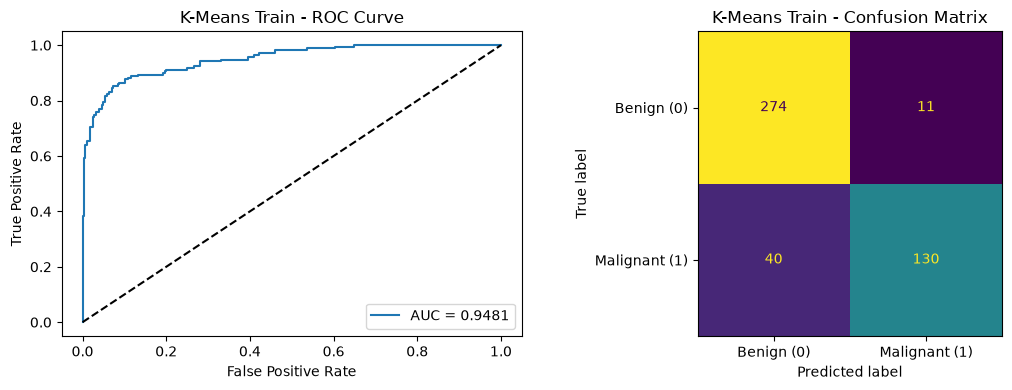

K-Means Average Training Metrics
accuracy     0.888498
precision    0.959027
recall       0.733137
f1           0.830593
auc          0.951126
dtype: float64


In [28]:
kmeans_train_metrics = []

for m, data in enumerate(kmeans_runs):
    X_train_norm = data["X_train_norm"]
    y_train = data["y_train"]
    train_clusters = data["train_clusters"]
    centers = data["centers"]
    cluster_to_label = {}
    fracs = []

    for c in [0, 1]:
        dists = np.linalg.norm(X_train_norm - centers[c], axis=1)
        closest_30_idx = np.argsort(dists)[:30]
        frac = np.mean(y_train[closest_30_idx])
        fracs.append(frac)
        cluster_to_label[c] = int(np.round(frac))

    if cluster_to_label[0] == cluster_to_label[1]:
        pos_c = int(np.argmax(fracs))
        cluster_to_label[pos_c] = 1
        cluster_to_label[1 - pos_c] = 0
    else:
        pos_c = [c for c, lbl in cluster_to_label.items() if lbl == 1][0]
        
    data["cluster_to_label"] = cluster_to_label
    data["pos_c"] = pos_c
    train_pred = np.array([cluster_to_label[c] for c in train_clusters])
    train_dists = cdist(X_train_norm, centers)
    train_probs = softmax(-train_dists, axis=1)[:, pos_c]
    kmeans_train_metrics.append(evaluate_metrics(y_train, train_pred, train_probs))
    
    if m == M - 1:
        plot_roc_and_cm(y_train, train_pred, train_probs, "K-Means Train")

km_train_df = pd.DataFrame(kmeans_train_metrics).mean()
print("K-Means Average Training Metrics")
print(km_train_df)

##### (C)

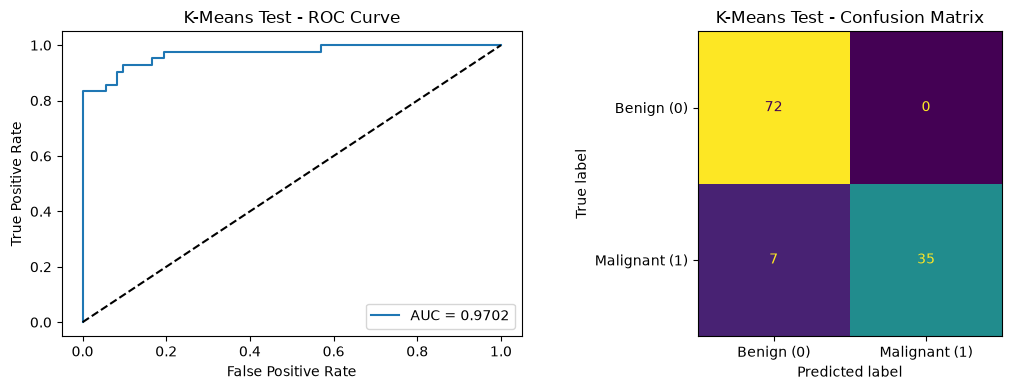

K-Means Average Test Metrics
accuracy     0.880117
precision    0.964111
recall       0.700794
f1           0.810250
auc          0.944433
dtype: float64


In [29]:
kmeans_test_metrics = []

for m, data in enumerate(kmeans_runs):
    X_test_norm = data["X_test_norm"]
    y_test = data["y_test"]
    centers = data["centers"]
    cluster_to_label = data["cluster_to_label"]
    pos_c = data["pos_c"]

    test_dists = cdist(X_test_norm, centers)
    test_clusters = np.argmin(test_dists, axis=1)
    test_pred = np.array([cluster_to_label[c] for c in test_clusters])
    test_probs = softmax(-test_dists, axis=1)[:, pos_c]
    kmeans_test_metrics.append(evaluate_metrics(y_test, test_pred, test_probs))
    
    if m == M - 1:
        plot_roc_and_cm(y_test, test_pred, test_probs, "K-Means Test")

km_test_df = pd.DataFrame(kmeans_test_metrics).mean()
print("K-Means Average Test Metrics")
print(km_test_df)

#### (iv) Spectral Clustering

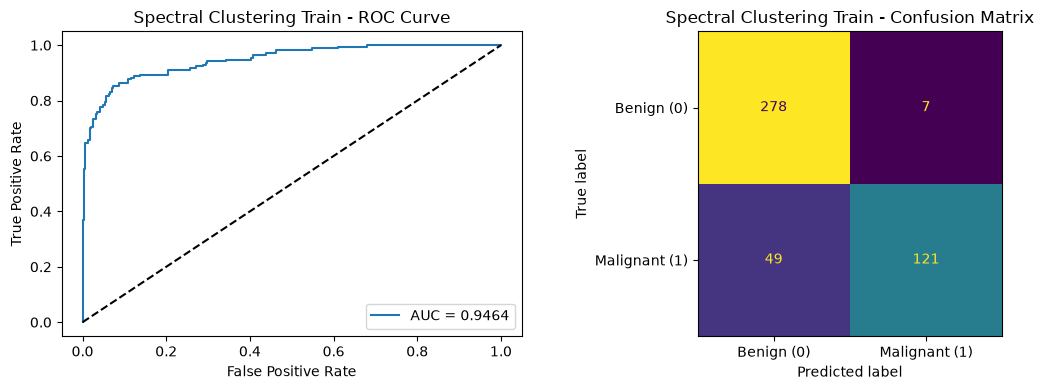

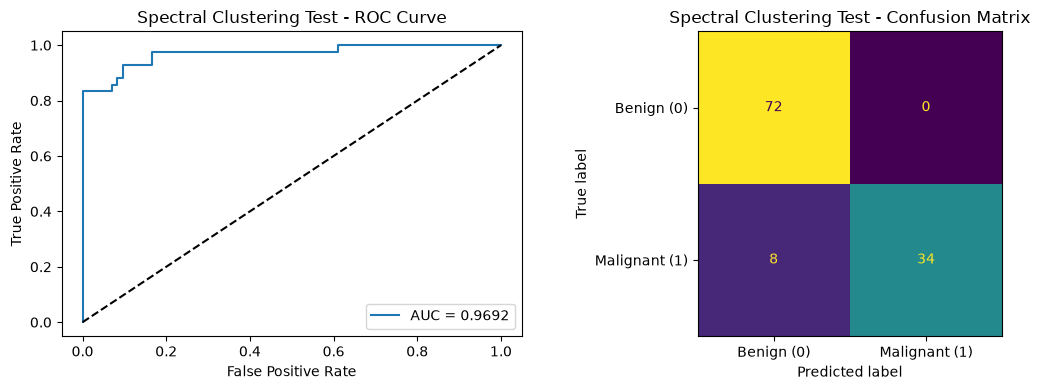

Spectral Clustering Average Metrics
              Train      Test
accuracy   0.883297  0.878947
precision  0.960396  0.964995
recall     0.717255  0.696825
f1         0.821060  0.808043
auc        0.950518  0.943717


In [30]:
spec_train_metrics, spec_test_metrics = [], []

for m in range(M):
    X_train, X_test, y_train, y_test = train_test_split(
        X_wdbc, y_wdbc, test_size=0.2, stratify=y_wdbc, random_state=m
    )
    
    scaler = Normalizer()
    X_train_norm = scaler.fit_transform(X_train)
    X_test_norm = scaler.transform(X_test)
    
    sc = SpectralClustering(
        n_clusters=2, affinity="rbf", gamma=1.0, assign_labels="kmeans", random_state=m
    )
    train_clusters = sc.fit_predict(X_train_norm)
    
    cluster_to_label = {}
    fracs = []
    for c in [0, 1]:
        idx = np.where(train_clusters == c)[0]
        frac = np.mean(y_train[idx]) if len(idx) > 0 else 0.0
        fracs.append(frac)
        cluster_to_label[c] = int(np.round(frac))
        
    if cluster_to_label[0] == cluster_to_label[1]:
        pos_c = int(np.argmax(fracs))
        cluster_to_label[pos_c] = 1
        cluster_to_label[1 - pos_c] = 0
    else:
        pos_c = [c for c, lbl in cluster_to_label.items() if lbl == 1][0]
        
    train_pred = np.array([cluster_to_label[c] for c in train_clusters])
    nc = NearestCentroid()
    nc.fit(X_train_norm, train_clusters)

    train_dists = cdist(X_train_norm, nc.centroids_)
    train_probs = softmax(-train_dists, axis=1)[:, pos_c]
    test_clusters = nc.predict(X_test_norm)
    test_pred = np.array([cluster_to_label[c] for c in test_clusters])
    test_dists = cdist(X_test_norm, nc.centroids_)
    test_probs = softmax(-test_dists, axis=1)[:, pos_c]
    spec_train_metrics.append(evaluate_metrics(y_train, train_pred, train_probs))
    spec_test_metrics.append(evaluate_metrics(y_test, test_pred, test_probs))
    
    if m == M - 1:
        plot_roc_and_cm(y_train, train_pred, train_probs, "Spectral Clustering Train")
        plot_roc_and_cm(y_test, test_pred, test_probs, "Spectral Clustering Test")

spec_train_df = pd.DataFrame(spec_train_metrics).mean()
spec_test_df = pd.DataFrame(spec_test_metrics).mean()
print("Spectral Clustering Average Metrics")
print(pd.DataFrame({"Train": spec_train_df, "Test": spec_test_df}))

#### (iv) Compare

In [31]:
comparison_test = pd.DataFrame({
    "Supervised": sup_test_df,
    "Semi-Supervised": semi_test_df,
    "Unsupervised": km_test_df,
    "Unsupervised": spec_test_df,
})

print(comparison_test.round(4))

           Supervised  Semi-Supervised  Unsupervised
accuracy       0.9564           0.9412        0.8789
precision      0.9512           0.9335        0.9650
recall         0.9302           0.9071        0.6968
f1             0.9400           0.9187        0.8080
auc            0.9923           0.9856        0.9437


Supervised Learning achieves the highest overall accuracy, f1-score, and AUC because it uses 100% of ground-truth labels to optimize the max-margin hyperplane directly.

Semi-Supervised Learning performs nearly as well as full supervised learning despite starting with only 50% of the labels. Iteratively pseudo-labeling points farthest from the decision boundary adds high-confidence points first, reinforcing the margin without introducing significant label noise.

Unsupervised Learning noticeably underperforms both other methods but still not too bad, since clustering relies purely on geometric/kernel similarity without label guidance during optimization, cluster boundaries do not align as cleanly with the true malignant decision boundary.

## 2. Active Learning Using Support Vector Machines

### (a) Download the banknote authentication Data Set

In [32]:
banknote = pd.read_csv("../data/data_banknote_authentication.txt", header=None)

X_bn = banknote.iloc[:, :-1].values
y_bn = banknote.iloc[:, -1].values

X_train_bn, X_test_bn, y_train_bn, y_test_bn = train_test_split(
    X_bn, y_bn, test_size=472, train_size=900, stratify=y_bn, random_state=42
)
print("Train shape:", X_train_bn.shape, "Test shape:", X_test_bn.shape)

Train shape: (900, 4) Test shape: (472, 4)


### (b) Repeat each of the following two procedures 50 times

#### (i) Passive

In [33]:
n_runs = 50
n_steps = 90 
C_grid_bn = {"C": np.logspace(-3, 4, 20)}

passive_errors = np.zeros((n_runs, n_steps))

for run in range(n_runs):
    rng = np.random.default_rng(run)
    
    while True:
        perm = rng.permutation(len(X_train_bn))
        if len(np.unique(y_train_bn[perm[:10]])) == 2:
            break
            
    for step in range(n_steps):
        k = (step + 1) * 10
        idx_pool = perm[:k]
        X_pool = X_train_bn[idx_pool]
        y_pool = y_train_bn[idx_pool]
        
        min_class_count = np.min(np.bincount(y_pool))
        n_splits = min(5, max(2, min_class_count))
        
        cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=run)
        clf = GridSearchCV(
            LinearSVC(penalty="l1", dual=False, max_iter=10000, random_state=run),
            param_grid=C_grid_bn,
            cv=cv,
            n_jobs=-1,
        )
        clf.fit(X_pool, y_pool)
        
        y_pred = clf.best_estimator_.predict(X_test_bn)
        passive_errors[run, step] = 1.0 - accuracy_score(y_test_bn, y_pred)

print("Final mean test error: ", passive_errors[:, -1].mean())

c:\Users\admins\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:1298: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
c:\Users\admins\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:1298: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
c:\Users\admins\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:1298: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
c:\Users\admins\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:1298: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
c:\Users\admins\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:1298: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  

Final mean test error:  0.008559322033898283


#### (ii) Active

In [34]:
active_errors = np.zeros((n_runs, n_steps))

for run in range(n_runs):
    rng = np.random.default_rng(run)
    all_indices = np.arange(len(X_train_bn))
    
    while True:
        init_idx = rng.choice(all_indices, size=10, replace=False)
        if len(np.unique(y_train_bn[init_idx])) == 2:
            break
            
    pool_idx = list(init_idx)
    remaining_idx = list(set(all_indices) - set(pool_idx))
    
    for step in range(n_steps):
        X_pool = X_train_bn[pool_idx]
        y_pool = y_train_bn[pool_idx]

        min_class_count = np.min(np.bincount(y_pool))
        n_splits = min(5, max(2, min_class_count))
        cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=run)
        clf = GridSearchCV(
            LinearSVC(penalty="l1", dual=False, max_iter=10000, random_state=run),
            param_grid=C_grid_bn,
            cv=cv,
            n_jobs=-1,
        )
        clf.fit(X_pool, y_pool)
        best_svm = clf.best_estimator_
        y_pred = best_svm.predict(X_test_bn)
        active_errors[run, step] = 1.0 - accuracy_score(y_test_bn, y_pred)
        
        if len(remaining_idx) > 0:
            X_rem = X_train_bn[remaining_idx]
            distances = np.abs(best_svm.decision_function(X_rem))
            closest_10_pos = np.argsort(distances)[:10]
            chosen = [remaining_idx[i] for i in closest_10_pos]
            pool_idx.extend(chosen)
            remaining_idx = [idx for idx in remaining_idx if idx not in set(chosen)]

print("Final mean test error: ", active_errors[:, -1].mean())

c:\Users\admins\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:1298: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
c:\Users\admins\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:1298: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
c:\Users\admins\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:1298: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
c:\Users\admins\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:1298: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
c:\Users\admins\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:1298: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  

Final mean test error:  0.00851694915254235


### (c) Average the 50 test errors

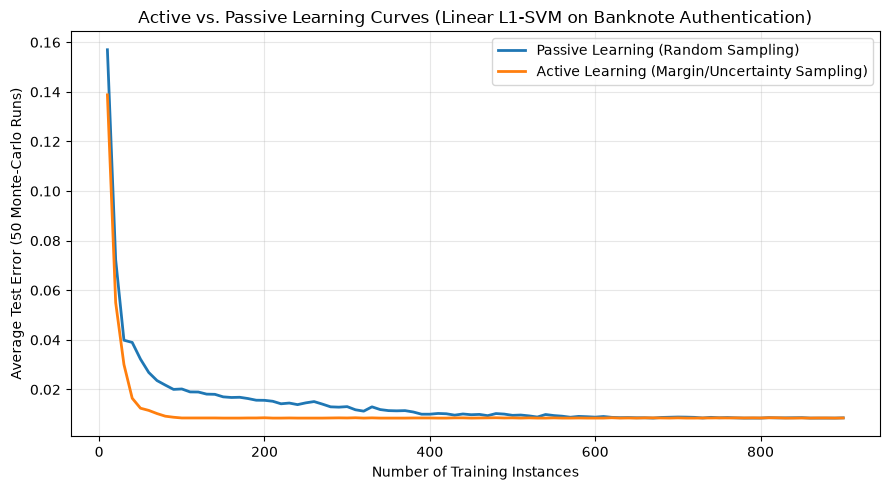

In [35]:
avg_passive_err = passive_errors.mean(axis=0)
avg_active_err = active_errors.mean(axis=0)
num_instances = np.arange(10, 901, 10)

plt.figure(figsize=(9, 5))
plt.plot(num_instances, avg_passive_err, label="Passive Learning (Random Sampling)", linewidth=2)
plt.plot(num_instances, avg_active_err, label="Active Learning (Margin/Uncertainty Sampling)", linewidth=2)
plt.xlabel("Number of Training Instances")
plt.ylabel("Average Test Error (50 Monte-Carlo Runs)")
plt.title("Active vs. Passive Learning Curves (Linear L1-SVM on Banknote Authentication)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Active learning has faster convergrance. Active learning reaches the asymptotic min test error much faster than passive learning—typically within 50 to 80 labeled instances, where passive learning requires way more instances to achieve comparable accuracy.

By selecting points closest to the current SVM hyperplane, active learning focuses labeling effort directly on refining the decision boundary rather than sampling redundant points deep inside already-classified regions. Once all 900 training points are included in the pool, both methods train on the exact same dataset and converge to the exact same test error.